## Inspect trained U2 ADAGE models

### November 8, 2026

### Mukundan Thanigaivelan

In this notebook, we take a look at the trained 50 models and see if any of them are good.

**Need to fix Google Drive Issue and Save Models, Loss History, KEGG Matrices, and all Plots!**

### Load libraries

In [1]:
# Prepend the correct prefix to load modules from adage/
import sys, os, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent.parent))

In [2]:
from m_adage import Adage, LinkedAE

from pandas import read_csv
import numpy as np
from sklearn.metrics import mean_squared_error
from tensorflow import zeros

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

from json import load
from zipfile import ZipFile
from types import SimpleNamespace

I0000 00:00:1794154519.007464 3469119 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794154519.011386 3469119 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794154519.064698 3469119 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/scratch/user/u.mt372094/conda/envs/uadage-conda/lib/python3.11/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).


### Load models

In [3]:
model_filenames = [
  f'../data/ec_U2_model_{i+1}.keras'
  for i in range(50)
]

In [4]:
# Load hyperparameters
with open('../data/ec_U2_model_hps.json', 'r') as f:
  optimal_hps = load(f)

In [5]:
train_comp = read_csv('../data/ecmg_lcn01_medmean_normal_muk.csv', index_col = 0)
loaded_models = []

for i, file in enumerate(model_filenames):
  # Create autoencoder object
  ae = LinkedAE.LinkedAE(
    input_dim = train_comp.shape[0],
    encoding_dim = optimal_hps['units'],
    act1 = optimal_hps['act1'],
    act2 = optimal_hps['act2'],
    dropout = optimal_hps['dropout'],
    kl1 = optimal_hps['kl1'],
    kl2 = optimal_hps['kl2'],
    init = optimal_hps['init'],
    tied = optimal_hps['tied'],
    u1 = optimal_hps['u1'],
    u2 = optimal_hps['u2'],
    reg_type = 'u2'
  )
  ae(zeros((1, train_comp.shape[0])))

  # Pull model weights
  with ZipFile(file) as z:
    z.extract('model.weights.h5')

  # Load saved weights
  ae.load_weights('model.weights.h5')

  # Delete extracted weights file
  os.remove('model.weights.h5')
  
  # Create ADAGE object
  adage = Adage.Adage(
    autoencoder = ae,
    history = SimpleNamespace(
      history = {
        'loss': np.loadtxt(
                  f'../data/ec_U2_model_loss_{i+1}.csv',
                  delimiter=','
                ).reshape(-1).tolist(),
        'val_loss': np.loadtxt(
                      f'../data/ec_U2_model_val_loss_{i+1}.csv',
                      delimiter=','
                    ).reshape(-1).tolist()
      }
    ),
    train_comp = train_comp
  )

  # Add model to list
  loaded_models.append(adage)

E0000 00:00:1794154827.852021 3469119 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


In [6]:
len(loaded_models)

50

### Reconstruction Error

In [7]:
x_train = train_comp.values.astype("float64").T
reconstruct_errors = []

for model in loaded_models:
  x_pred = model.autoencoder.predict(x_train, verbose = 0)
  mse = mean_squared_error(x_train.flatten(), x_pred.flatten())
  reconstruct_errors.append(mse)

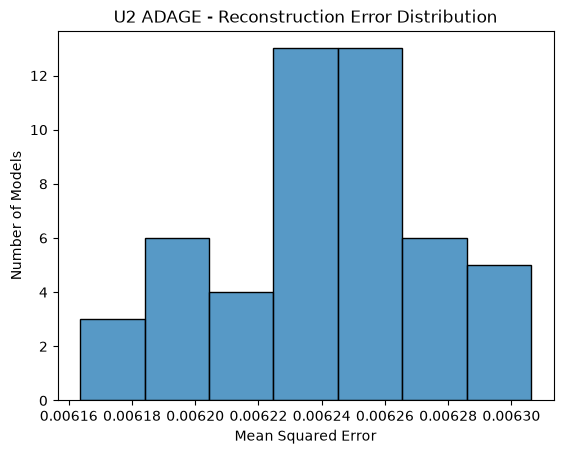

In [9]:
# Plot distribution of reconstruction error across models
ax = sns.histplot(reconstruct_errors)

plt.title("U2 ADAGE - Reconstruction Error Distribution")
plt.xlabel("Mean Squared Error")
plt.ylabel("Number of Models")

# Save plot locally
plot_path = '../data/ec_U2_recon_err.png'
plt.savefig(
  plot_path,
  dpi = 300,
  bbox_inches = 'tight'
)

# Save plot in drive
# !rclone copy '{plot_path}' mygdrive:'Mukundan - Senior Project/U2 Models/plots/'

### KEGG Enrichment

In [10]:
# Create enrichment matrices
kegg_dfs = []

for model in loaded_models:
  ec_kegg_ps = model.set_kegg('../data/filtered_ec_kegg_pathways.tsv')
  kegg_dfs.append(ec_kegg_ps)

In [11]:
# Save sum of p-values across each matrix to lists
p_val_sums = []

for df in kegg_dfs:
  p_val_sums.append(df.sum().sum())

In [12]:
# Inspect p-values
p_val_sums

[np.float64(89.0854704685435),
 np.float64(78.84250791622594),
 np.float64(132.38468519190107),
 np.float64(129.6042731032165),
 np.float64(133.30815705591007),
 np.float64(52.03952508400234),
 np.float64(104.59577702634749),
 np.float64(160.00843028439775),
 np.float64(118.79481091117077),
 np.float64(76.50498954983148),
 np.float64(138.0877472463566),
 np.float64(96.02428555525668),
 np.float64(128.2323849399346),
 np.float64(138.12236194401507),
 np.float64(97.56305576114693),
 np.float64(67.40194570556577),
 np.float64(129.51718172939263),
 np.float64(119.06534914954989),
 np.float64(106.60314581306744),
 np.float64(130.35584572104156),
 np.float64(112.10367819097061),
 np.float64(117.69419613501545),
 np.float64(63.64076374823178),
 np.float64(146.31685456313502),
 np.float64(151.56320217488465),
 np.float64(131.9861933027957),
 np.float64(81.81626786224524),
 np.float64(157.67814486005767),
 np.float64(70.03864417603394),
 np.float64(65.65636898637892),
 np.float64(119.2361175818

In [13]:
# Save KEGG enrichment matrices for all models
for i, df in enumerate(kegg_dfs):
  kegg_path = f'../data/ec_U2_kegg_matrix_{i+1}.csv'
  df.to_csv(kegg_path)
  # !rclone copy '{kegg_path}' mygdrive:'Mukundan - Senior Project/U2 Models/kegg_dfs/'

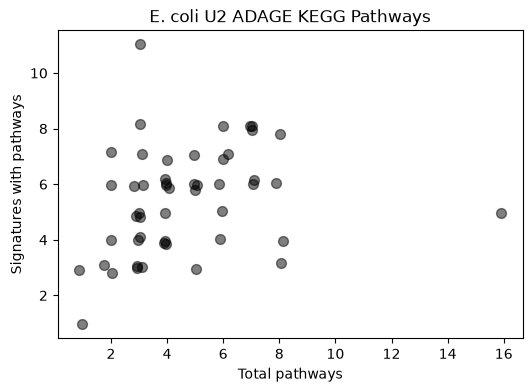

In [16]:
# Plot number of enriched KEGG pathways
plt.figure(figsize = (6, 4))
np.random.seed(42)

for df in kegg_dfs:
  x = ((df > 2.5).sum(axis = 0) > 0).sum()
  y = ((df > 2.5).sum(axis = 1) > 0).sum()

  # Add small jitter
  x_jittered = x + np.random.normal(0, 0.1)
  y_jittered = y + np.random.normal(0, 0.1)

  plt.scatter(
    x_jittered, 
    y_jittered,
    alpha = 0.5, 
    color = "black", 
    s = 50
  )

plt.title('E. coli U2 ADAGE KEGG Pathways')
plt.xlabel('Total pathways')
plt.ylabel('Signatures with pathways')

# Save figure locally
plot_path = '../data/ec_U2_kegg.png'
plt.savefig(
  plot_path,
  dpi = 300,
  bbox_inches = 'tight'
)

# Save plot in drive
# !rclone copy '{plot_path}' mygdrive:'Mukundan - Senior Project/U2 Models/plots/'

### Training Loss Curves

In [17]:
# Create a NumPy 2D array of losses, where each array is for each model
train_losses = np.array([
  model.history.history['loss']
  for model in loaded_models
])

val_losses = np.array([
  model.history.history['val_loss']
  for model in loaded_models
])

n_models, n_epochs = train_losses.shape
epochs = np.arange(n_epochs)

In [18]:
# Calculate median loss across models at each epoch
train_median = np.median(train_losses, axis=0)
val_median = np.median(val_losses, axis=0)

# Calculate 25th and 75th percentiles
train_q25, train_q75 = np.percentile(
  train_losses, [25, 75], axis=0
)
val_q25, val_q75 = np.percentile(
  val_losses, [25, 75], axis=0
)

# Calculate 10th and 90th percentiles
train_q10, train_q90 = np.percentile(
  train_losses, [10, 90], axis=0
)
val_q10, val_q90 = np.percentile(
  val_losses, [10, 90], axis=0
)

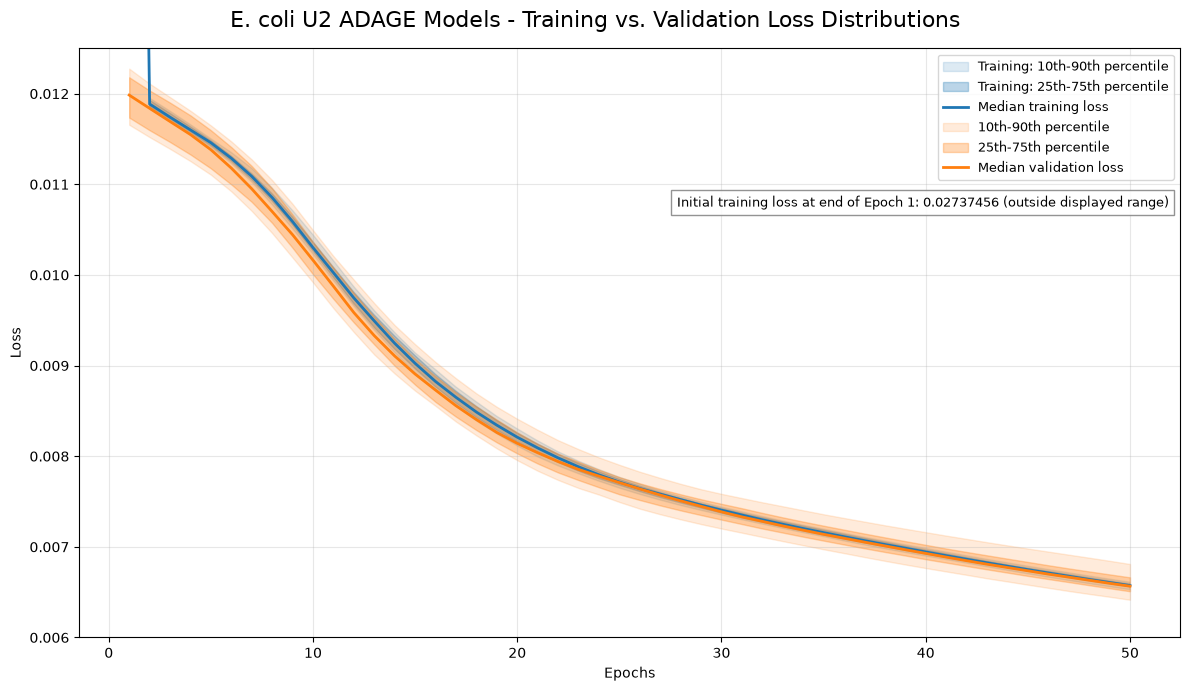

In [25]:
fig, ax = plt.subplots(figsize=(12, 7))

fig.suptitle(
  'E. coli U2 ADAGE Models - Training vs. Validation Loss Distributions',
  fontsize = 16
)
plt.style.use('tableau-colorblind10')

# *** Plot training loss *** #

# Plot 10th - 90th percentile outside
ax.fill_between(
  epochs + 1,
  train_q10,
  train_q90,
  color = 'tab:blue',
  alpha = 0.15,
  label = 'Training: 10th-90th percentile'
)

# Plot 25th - 75th percentile inside
ax.fill_between(
  epochs + 1,
  train_q25,
  train_q75,
  color = 'tab:blue',
  alpha = 0.3,
  label = 'Training: 25th-75th percentile'
)

# Median training loss
ax.plot(
  epochs + 1,
  train_median,
  color = 'tab:blue',
  linewidth = 2,
  label = 'Median training loss'
)

# *** Plot validation loss *** #

# Plot 10th - 90th percentile outside
ax.fill_between(
  epochs + 1,
  val_q10,
  val_q90,
  color = 'tab:orange',
  alpha = 0.15,
  label = '10th-90th percentile'
)

# Plot 25th - 75th percentile inside
ax.fill_between(
  epochs + 1,
  val_q25,
  val_q75,
  color = 'tab:orange',
  alpha = 0.3,
  label = '25th-75th percentile'
)

# Median validation loss
ax.plot(
  epochs + 1,
  val_median,
  color = 'tab:orange',
  linewidth = 2,
  label = 'Median validation loss'
)

ax.set(
  xlabel = 'Epochs',
  ylabel = 'Loss'
)
ax.grid(alpha = 0.3)

ax.legend(
    loc='best',
    fontsize=9
)

ax.set_ylim(0.006, 0.0125)
ax.text(
  0.99, 
  0.75,
  'Initial training loss at end of Epoch 1: 0.02737456 (outside displayed range)',
  transform = ax.transAxes,
  fontsize = 9,
  ha = 'right',
  va = 'top',
  bbox = dict(
    facecolor = 'white',
    alpha = 0.85,
    edgecolor = 'gray'
  )
)

plt.tight_layout()

# Save figure locally
plot_path = '../data/ec_U2_loss_dist.png'
fig.savefig(
  plot_path,
  dpi = 300,
  bbox_inches = 'tight'
)

# Save plot in drive
# !rclone copy '{plot_path}' mygdrive:'Mukundan - Senior Project/U2 Models/plots/'

### Weight Distributions

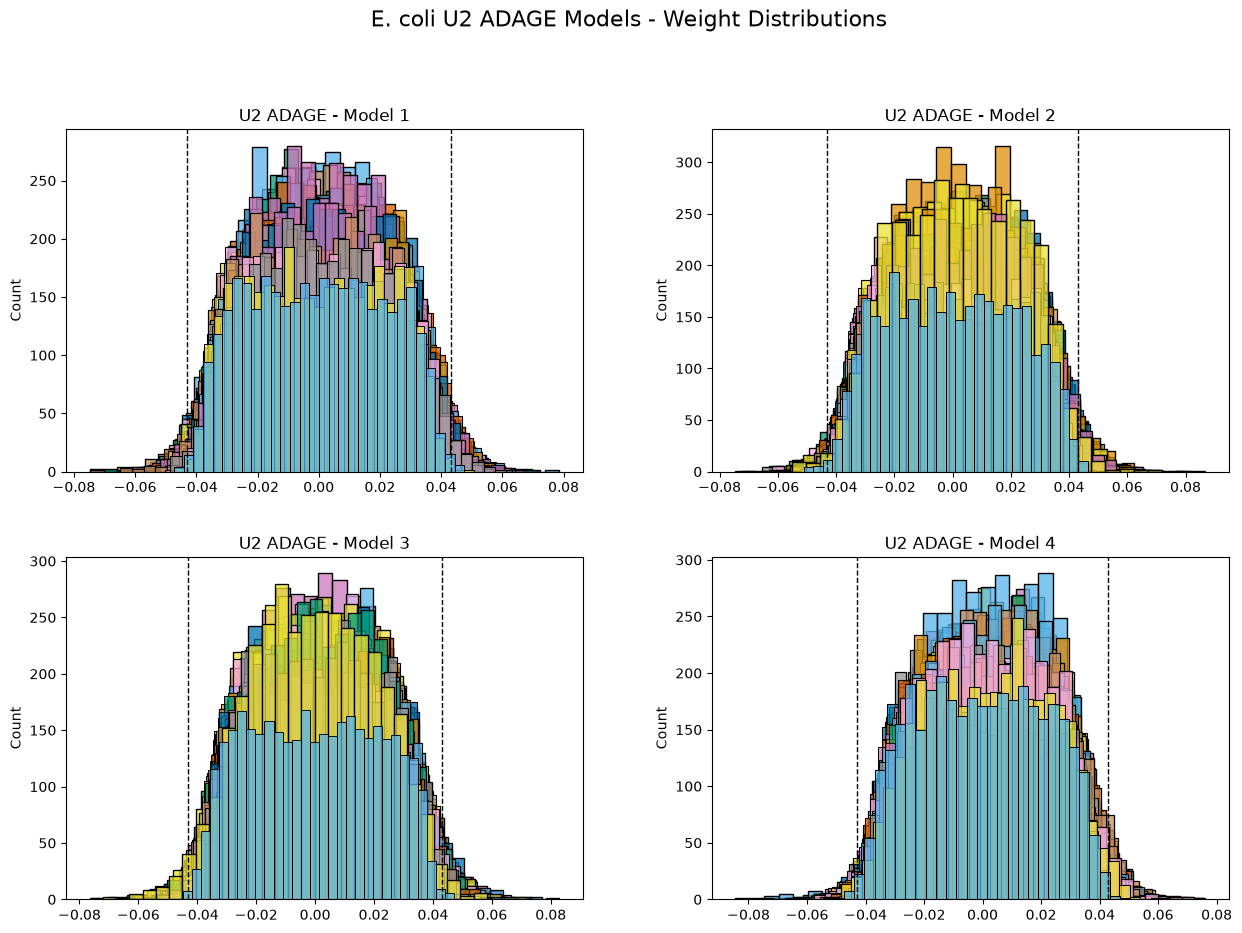

In [27]:
plot_titles = [
  f'U2 ADAGE - Model {i+1}'
  for i in range(4)
]

fig, ax = plt.subplots(2, 2, figsize = (15, 10))
fig.subplots_adjust(hspace = 0.25, wspace = 0.25)

fig.suptitle(
  'E. coli U2 ADAGE Models - Weight Distributions',
  fontsize = 16,
  y = 1
)
colorblind_colors = sns.color_palette("colorblind")

for i in range(2):
  for j in range(2):
    weights_matrix = np.asarray(loaded_models[2*i + j].autoencoder.get_weights()[0])

    for node in range(optimal_hps['units']):
      weights = weights_matrix[:, node]
      weights = weights[np.isfinite(weights)]

      # Skip empty arrays and constant distributions
      if len(weights) == 0 or np.min(weights) == np.max(weights):
        continue

      # Each hidden node weight distribution
      sns.histplot(
        weights,
        ax = ax[i, j],
        bins = 30,
        color = colorblind_colors[node % len(colorblind_colors)],
        kde = False
      )

    all_weights = weights_matrix.flatten()
    all_weights = all_weights[np.isfinite(all_weights)]
    cutoff = np.std(all_weights) * 2

    ax[i, j].axvline(
      x = cutoff,
      color = 'black',
      linestyle = '--',
      linewidth = 1
    )
    ax[i, j].axvline(
      x = -cutoff,
      color = 'black',
      linestyle = '--',
      linewidth = 1
    )
    ax[i, j].set(title = plot_titles[2*i + j])

# Save figure locally
plot_path = '../data/ec_U2_weight_dist.png'
fig.savefig(
  plot_path,
  dpi = 300,
  bbox_inches = 'tight'
)

# Save plot in drive
# !rclone copy '{plot_path}' mygdrive:'Mukundan - Senior Project/U2 Models/plots/'